In [1]:

import time
import numpy as np
import matplotlib.pyplot as plt
from pyscf import gto, dft
from pyscf.dft import gen_grid

HARTREE2KCAL = 627.5096080305927

/home/lector/python-QChem/lib/python3.9/site-packages/pyscf/dft/libxc.py:772: UserWarning: Since PySCF-2.3, B3LYP (and B3P86) are changed to the VWN-RPA variant, the same to the B3LYP functional in Gaussian and ORCA (issue 1480). To restore the VWN5 definition, you can put the setting "B3LYP_WITH_VWN5 = True" in pyscf_conf.py
  warnings.warn('Since PySCF-2.3, B3LYP (and B3P86) are changed to the VWN-RPA variant, '


In [2]:
func_str1 = '0.33*HF + 0.67*PBE, PBE'
func_str2 = '0.67*HF + 0.33*PBE, PBE'
func_str3 = '1*HF + 0*PBE , PBE'

mol_xyz = """6
Ethylene experimental geometry (NIST CCCBDB)
  C   0.00000000   0.00000000   0.66950000
  C   0.00000000   0.00000000  -0.66950000
  H   0.92892559   0.00000000   1.23207733
  H  -0.92892559   0.00000000   1.23207733
  H   0.92892559   0.00000000  -1.23207733
  H  -0.92892559   0.00000000  -1.23207733
"""
mol = gto.Mole()
mol.atom = '\n'.join(mol_xyz.split('\n')[2:])
mol.basis = 'def2-svp'
mol.build()

In [3]:
mf1 = dft.RKS(mol, xc = func_str1).run()
mf2 = dft.RKS(mol, xc = func_str2).run()
mf3 = dft.RKS(mol, xc = func_str3).run()

converged SCF energy = -78.4301617817458
converged SCF energy = -78.4528686337406
converged SCF energy = -78.4773646386579


In [4]:
HARTREE2EV   = 27.211386245988

homo = mol.nelec[0] - 1 
lumo = homo + 1
results = {}
results["33%"] = (mf1.e_tot, mf1.mo_energy[homo]*HARTREE2EV, mf1.mo_energy[lumo]*HARTREE2EV, mf1.converged)
results["67%"] = (mf2.e_tot, mf2.mo_energy[homo]*HARTREE2EV, mf2.mo_energy[lumo]*HARTREE2EV, mf2.converged)
results["100%"] = (mf3.e_tot, mf3.mo_energy[homo]*HARTREE2EV, mf3.mo_energy[lumo]*HARTREE2EV, mf3.converged)


In [5]:
print(f'HOMO-LUMO GAP для PBE(33% HF) {(mf1.mo_energy[lumo]- mf1.mo_energy[homo])*HARTREE2EV }')
print(f'HOMO-LUMO GAP для PBE(67% HF) {(mf2.mo_energy[lumo]- mf2.mo_energy[homo])*HARTREE2EV }')
print(f'HOMO-LUMO GAP для PBE(100% HF) {(mf3.mo_energy[lumo]- mf3.mo_energy[homo])*HARTREE2EV }')


HOMO-LUMO GAP для PBE(33% HF) 8.809878812452938
HOMO-LUMO GAP для PBE(67% HF) 11.84919116946324
HOMO-LUMO GAP для PBE(100% HF) 14.754835542671168


In [6]:
CN_xyz = """ 6
Experimental geometry from NIST CCCBDB (C3v)
C        0.000000        0.000000       0.0000000
C        0.000000        0.000000       1.4580
N        0.000000        0.000000       2.6150
H        0.000000        1.040200       -0.3675
H       0.9016    -0.520500       -0.3675
H       0.9016       0.520500       -0.3675
"""
mol = gto.Mole()
mol.atom = '\n'.join(CN_xyz.split('\n')[2:])
mol.basis = 'def2-svp'
mol.build()

In [7]:
levels = [0, 1, 3, 5]
energies = {}

for lvl in levels:
    mf = dft.RKS(mol)
    mf.xc = 'PBE'
    mf.grids.level = lvl
    mf.conv_tol = 1e-10
    mf.run()
    energies[lvl] = mf.e_tot

converged SCF energy = -132.316572668587
converged SCF energy = -132.342195931408
converged SCF energy = -132.342190948529
converged SCF energy = -132.342190007949


In [8]:
ref = energies[5]
print(f"{'level':>5s} {'E_tot, Хартри':>18s}  {' Разница с 5,ккал/моль':>11s}")
for lvl in levels:
    dE = energies[lvl] - ref
    print(f"{lvl:5d} {energies[lvl]:18.10f} {dE*HARTREE2KCAL:11.5f}")

level      E_tot, Хартри   Разница с 5,ккал/моль
    0    -132.3165726686    16.07513
    1    -132.3421959314    -0.00372
    3    -132.3421909485    -0.00059
    5    -132.3421900079     0.00000


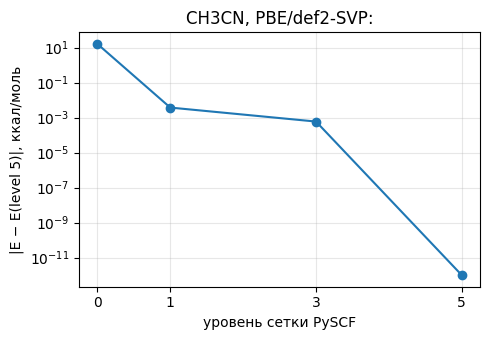

In [13]:

HARTREE2KCAL = 627.5096080305927

dE_kcal = [abs(energies[l] - ref)*HARTREE2KCAL for l in levels]

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.semilogy(levels, [max(d, 1e-12) for d in dE_kcal], 'o-')
ax.set_xticks(levels)
ax.set_xlabel('уровень сетки PySCF')
ax.set_ylabel('|E − E(level 5)|, ккал/моль')
ax.set_title('CH3CN, PBE/def2-SVP:')
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig('CH3CN_grid_levels.png', dpi=150); plt.show()